# D7041E Applied Artificial Intelligence <BR>
## Lab 2 - HD, SOM and Backpropagation
Dominic Addo - domadd-2@student.ltu.se <br>
Abdalrahman Nasser - abdnas-2@student.ltu.se

## Task 1 - Language Classification with Hyperdimensional Computing

### Task 1.1 -Import Datasets and Preprocessing

#### Import datasets and libraries

In [1]:
import os
import pandas as pd
import numpy as np
import re
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, classification_report
from pathlib import Path
import glob
import matplotlib.pyplot as plt
import seaborn as sns
import time
from tqdm import tqdm

# Set random seed for reproducibility
np.random.seed(42)

#### Define the directory structure

In [2]:
# Define all paths
base_dir = Path('./data')
leipzig_dir = base_dir / 'leipzig'
europarl_dir = base_dir / 'europarl'
processed_dir = base_dir / 'processed'

# Create processed directory and subdirectories
(processed_dir / 'leipzig').mkdir(parents=True, exist_ok=True)
(processed_dir / 'europarl').mkdir(parents=True, exist_ok=True)

# Verify paths exist
print("Directory Structure:")
print(f"  Base: {base_dir.absolute()}")
print(f"  Leipzig: {leipzig_dir.absolute()} - {'Yes' if leipzig_dir.exists() else 'No, NOT FOUND'}")
print(f"  Europarl: {europarl_dir.absolute()} - {'Yes' if europarl_dir.exists() else 'No, NOT FOUND'}")
print(f"  Processed: {processed_dir.absolute()} - Yes")

Directory Structure:
  Base: c:\Users\addod\Applied AI Lab work\lab2_HD_SOM_BACKPROP\data
  Leipzig: c:\Users\addod\Applied AI Lab work\lab2_HD_SOM_BACKPROP\data\leipzig - Yes
  Europarl: c:\Users\addod\Applied AI Lab work\lab2_HD_SOM_BACKPROP\data\europarl - Yes
  Processed: c:\Users\addod\Applied AI Lab work\lab2_HD_SOM_BACKPROP\data\processed - Yes


#### Language mapping for the datasets

In [3]:
# Language mapping: 2-letter codes to full names
LANGUAGE_MAP = {
    "bg": "Bulgarian", "cs": "Czech", "da": "Danish", "de": "German",
    "el": "Greek", "en": "English", "et": "Estonian", "fi": "Finnish",
    "fr": "French", "hu": "Hungarian", "it": "Italian", "lv": "Latvian",
    "lt": "Lithuanian", "nl": "Dutch", "pl": "Polish", "pt": "Portuguese",
    "ro": "Romanian", "sk": "Slovak", "sl": "Slovenian", "es": "Spanish",
    "sv": "Swedish"
}

# Leipzig uses 3-letter codes
LEIPZIG_MAP = {
    'bul': 'bg', 'ces': 'cs', 'dan': 'da', 'deu': 'de', 'ell': 'el',
    'eng': 'en', 'est': 'et', 'fin': 'fi', 'fra': 'fr', 'hun': 'hu',
    'ita': 'it', 'lav': 'lv', 'lit': 'lt', 'nld': 'nl', 'pol': 'pl',
    'por': 'pt', 'ron': 'ro', 'slk': 'sk', 'slv': 'sl', 'spa': 'es', 'swe': 'sv'
}

print(f"Language mappings defined for {len(LANGUAGE_MAP)} languages")
print(f"Languages: {sorted(LANGUAGE_MAP.values())}")

Language mappings defined for 21 languages
Languages: ['Bulgarian', 'Czech', 'Danish', 'Dutch', 'English', 'Estonian', 'Finnish', 'French', 'German', 'Greek', 'Hungarian', 'Italian', 'Latvian', 'Lithuanian', 'Polish', 'Portuguese', 'Romanian', 'Slovak', 'Slovenian', 'Spanish', 'Swedish']


#### Function for cleaning text data

In [4]:
#Preprocesses text for HD Language ID.
def clean_text_preserving_accents(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = ''.join(char for char in text if char.isalpha() or char.isspace())
    text = re.sub(r'\s+', ' ', text)
    
    return text.strip()


#### Function for loading and preprocessing Leipzig dataset

In [5]:
def load_and_process_leipzig_data(base_path, min_length=20):
    
    output_path = processed_dir / 'leipzig' / 'leipzig_processed.csv'
    
    # Check if already processed
    if output_path.exists():
        print("Leipzig data already processed. Loading from: ", output_path)
        df = pd.read_csv(output_path)
        print(f"  Loaded {len(df):,} sentences across {df['lang_code'].nunique()} languages\n")
        return df
    
    all_data = []
    search = os.path.join(base_path, '**', '*sentences.txt')
    files = glob.glob(search, recursive=True)
    
    print(f"Found {len(files)} sentence files in '{base_path}\n")

    for file_path in files:
        filename = os.path.basename(file_path)
        
        # Extract 3-letter language code from filename
        file_lang_code = filename[:3]
        
        if file_lang_code not in LEIPZIG_MAP:
            print(f"Skipping unsupported language: {filename}")
            continue
        
        # Convert to 2-letter code and full name
        two_letter_code = LEIPZIG_MAP[file_lang_code]
        language_name = LANGUAGE_MAP[two_letter_code]
        
        try:
            # Read the TSV file (ID\tSentence format)
            df = pd.read_csv(
                file_path, 
                sep='\t', 
                header=None, 
                names=['id', 'sentence'], 
                quoting=3,
                on_bad_lines='skip',
                encoding='utf-8'
            )
            
            # Apply Preprocessing
            df['cleaned_sentence'] = df['sentence'].apply(clean_text_preserving_accents)
            
            # Filter length (remove empty or extremely short lines after cleaning)
            df = df[df['cleaned_sentence'].str.len() >= min_length].copy()
            
            # Add labels
            df['lang_code'] = language_name
            
            # Append only necessary columns to save memory
            all_data.append(df[['cleaned_sentence', 'lang_code']])
            
            print(f"Loaded {len(df)} valid sentences.")
            
        except Exception as e: 
             print(f"ERROR processing file {filename}: {e}")
                 
    final_df = pd.concat(all_data, ignore_index=True)
    
    # Shuffle the dataset immediately to mix languages
    final_df = final_df.sample(frac=1, random_state=42).reset_index(drop=True)
    
    output_path = processed_dir / 'leipzig' / 'leipzig_processed.csv'
    final_df.to_csv(output_path, index=False, encoding='utf-8')
    
    print(f"Total loaded: {len(final_df)} sentences across {final_df['lang_code'].nunique()} languages.\n")
    
    return final_df

#### Function for loading and preprocessing Europarl dataset

In [6]:
def load_and_process_europarl_data(base_path, sample_size=5000, min_length=20):
    
    output_path = processed_dir / 'europarl' / 'europarl_processed.csv'
    txt_dir = Path(base_path) / 'txt'
    
    # Check if already processed
    if output_path.exists():
        print("Europarl data already processed. Loading from: ", output_path)
        df = pd.read_csv(output_path)
        print(f"  Loaded {len(df):,} sentences across {df['lang_code'].nunique()} languages\n")
        return df
    
    all_data = []
    
    # Get all language folders
    lang_folders = [d for d in txt_dir.iterdir() if d.is_dir()]
    
    for lang_folder in sorted(lang_folders):
        lang_code = lang_folder.name
        if lang_code not in LANGUAGE_MAP:
            print(f"Skipping unsupported language folder: {lang_code}")
            continue
        
        language_name = LANGUAGE_MAP[lang_code]
        print(f"Processing {language_name} ({lang_code})...")
        
        # Get all .txt files in the language folder
        lang_files = list(lang_folder.glob('ep-*.txt'))
        
        lang_sentences = []
        
        # Read each file and collect sentences for that language
        for file_path in lang_files:
            try:
                with open(file_path, 'r', encoding='utf-8') as f:
                    for line in f:
                        line = line.strip()
                        # Skip empty lines and XML tags
                        if not line or line.startswith('<'):
                            continue
                        lang_sentences.append(line)
            except Exception as e:
                print(f"ERROR reading file {file_path.name}: {e}")
        
        # Create DataFrame
        df = pd.DataFrame(lang_sentences, columns=['sentence'])
        
        # Apply Preprocessing
        df['cleaned_sentence'] = df['sentence'].apply(clean_text_preserving_accents)
        
        # Filter length
        df = df[df['cleaned_sentence'].str.len() >= min_length].copy()
        
        # Sample data
        if len(df) > sample_size:
            df = df.sample(n=sample_size, random_state=42)
        elif len(df) < sample_size:
            print(f"Only {len(df)} sentences (less than {sample_size})")
        
        # Add language label
        df['lang_code'] = language_name
        
        all_data.append(df[['cleaned_sentence', 'lang_code']])
        
    # Combine all data
    final_df = pd.concat(all_data, ignore_index=True)
    
    # Shuffle dataset
    final_df = final_df.sample(frac=1, random_state=42).reset_index(drop=True)
    
    # Save to processed directory
    final_df.to_csv(output_path, index=False, encoding='utf-8')
        
    print(f"Loaded {len(final_df)} sentences in total.")
    print(f"Saved processed Europarl data to {output_path}\n")
    
    return final_df

#### Processing the Leipzig and Europarl datasets

In [7]:
# Process Leipzig
leipzig_data = load_and_process_leipzig_data(leipzig_dir)

# Process Europarl
europarl_data = load_and_process_europarl_data(europarl_dir)

Leipzig data already processed. Loading from:  data\processed\leipzig\leipzig_processed.csv
  Loaded 2,183,786 sentences across 21 languages

Europarl data already processed. Loading from:  data\processed\europarl\europarl_processed.csv
  Loaded 105,000 sentences across 21 languages



#### Verifying the processed datasets

In [8]:
print("Verifying processed datasets...\n")

# Check Leipzig
leipzig_processed = processed_dir / 'leipzig' / 'leipzig_processed.csv'
if leipzig_processed.exists():
    df_leipzig = pd.read_csv(leipzig_processed)
    print(f"\nLeipzig: {leipzig_processed}")
    print(f"  Rows: {len(df_leipzig):,}")
    print(f"  Languages: {df_leipzig['lang_code'].nunique()}")
    print(f"  File size: {leipzig_processed.stat().st_size / 1024 / 1024:.2f} MB")
    print(f"\n  Language distribution:")
    lang_dist = df_leipzig['lang_code'].value_counts().sort_index()
    for lang, count in lang_dist.items():
        print(f"    {lang}: {count:,}")
else:
    print(f"\nLeipzig file not found")

# Check Europarl
europarl_processed = processed_dir / 'europarl' / 'europarl_processed.csv'
if europarl_processed.exists():
    df_europarl = pd.read_csv(europarl_processed)
    print(f"\nEuroparl: {europarl_processed}")
    print(f"  Rows: {len(df_europarl):,}")
    print(f"  Languages: {df_europarl['lang_code'].nunique()}")
    print(f"  File size: {europarl_processed.stat().st_size / 1024 / 1024:.2f} MB")
    print(f"\n  Language distribution:")
    lang_dist = df_europarl['lang_code'].value_counts().sort_index()
    for lang, count in lang_dist.items():
        print(f"    {lang}: {count:,}")
else:
    print(f"\nEuroparl file not found")
    

Verifying processed datasets...


Leipzig: data\processed\leipzig\leipzig_processed.csv
  Rows: 2,183,786
  Languages: 21
  File size: 253.86 MB

  Language distribution:
    bg: 98,111
    cs: 197,812
    da: 99,470
    de: 99,627
    el: 99,238
    en: 99,281
    es: 99,708
    et: 99,288
    fi: 99,639
    fr: 99,509
    hu: 99,577
    it: 99,474
    lt: 99,184
    lv: 99,381
    nl: 98,823
    pl: 98,885
    pt: 99,382
    ro: 99,147
    sk: 99,454
    sl: 99,459
    sv: 99,337

Europarl: data\processed\europarl\europarl_processed.csv
  Rows: 105,000
  Languages: 21
  File size: 48.83 MB

  Language distribution:
    Bulgarian: 5,000
    Czech: 5,000
    Danish: 5,000
    Dutch: 5,000
    English: 5,000
    Estonian: 5,000
    Finnish: 5,000
    French: 5,000
    German: 5,000
    Greek: 5,000
    Hungarian: 5,000
    Italian: 5,000
    Latvian: 5,000
    Lithuanian: 5,000
    Polish: 5,000
    Portuguese: 5,000
    Romanian: 5,000
    Slovak: 5,000
    Slovenian: 5,000
    Spanish

#### Verify the preprocessed Leipzig and Europarl files

In [9]:
# Checking processed Leipzig data
leipzig_processed = processed_dir / 'leipzig' / 'leipzig_processed.csv'
if leipzig_processed.exists():
    df_leipzig = pd.read_csv(leipzig_processed)
    print(f"Processed Leipzig: {leipzig_processed}")
    print(f"  Rows: {len(df_leipzig):,}")
    print(f"  Languages: {df_leipzig['lang_code'].nunique()}")
    print(f"  File size: {leipzig_processed.stat().st_size / 1024 / 1024:.2f} MB\n")
else:
    print(f"Leipzig csv file not found\n")


# cHecking processed Europarl data
europarl_processed = processed_dir / 'europarl' / 'europarl_processed.csv'
if europarl_processed.exists():
    df_europarl = pd.read_csv(europarl_processed)
    print(f"Processed Europarl: {europarl_processed}")
    print(f"  Rows: {len(df_europarl):,}")
    print(f"  Languages: {df_europarl['lang_code'].nunique()}")
    print(f"  File size: {europarl_processed.stat().st_size / 1024 / 1024:.2f} MB\n")
else:
    print(f"Europarl csv file not found\n")

Processed Leipzig: data\processed\leipzig\leipzig_processed.csv
  Rows: 2,183,786
  Languages: 21
  File size: 253.86 MB

Processed Europarl: data\processed\europarl\europarl_processed.csv
  Rows: 105,000
  Languages: 21
  File size: 48.83 MB



#### Processing the Leipzig CSV files and splitting it into training, validation, and test sets

In [10]:
def convert_csv_to_train_test(csv_path, test_size=0.2):
    df = pd.read_csv(csv_path)
    full_train, test_data = train_test_split(
        df, 
        test_size=test_size, 
        random_state=42, 
        stratify=df['lang_code']
    )
    
    train_data, val_data = train_test_split(
        full_train, 
        test_size=0.2, 
        random_state=42, 
        stratify=full_train['lang_code']
    )
    
    return train_data, val_data, test_data

# Print some samples from the datasets
train_leipzig, val_leipzig, test_leipzig = convert_csv_to_train_test(leipzig_processed)
print("Leipzig Training samples:")
print(train_leipzig.sample(5, random_state=42)[['cleaned_sentence', 'lang_code']].to_string(index=False))
print("\nLeipzig Validation samples:")
print(val_leipzig.sample(5, random_state=42)[['cleaned_sentence', 'lang_code']].to_string(index=False))
print("\nLeipzig Test samples:")
print(test_leipzig.sample(5, random_state=42)[['cleaned_sentence', 'lang_code']].to_string(index=False))

Leipzig Training samples:
                                                                                                                                                                                cleaned_sentence lang_code
                                                                                                                             hugo moyano a macri lo mandan a decir cosas y no sabe transmitirlas        es
                                                                                                                                          ecco una tabella riepilogativa delle novità e un video        it
       to jest wróżenie z fusów ale wydaje mi się że zimna wojna ma szansę na statuetkę tylko jeśli roma dostając nagrodę za najlepszy film nie weźmie oscara za najlepszy film nieanglojęzyczny        pl
senovinės stiklo taurės gražiai atrodys šalia šiuolaikiško dizaino indų ir stalo įrankių o tradicines žvakes puikiai papildys stikliniai gaubtai su led lempučių g

#### Reading the Europarl CSV data

In [11]:
# Final evaluation test set from Europarl
final_eu_df = pd.read_csv(europarl_processed)
final_europarl_test = train_test_split(
        final_eu_df, 
        random_state=42, 
        stratify=final_eu_df['lang_code']
    )

print(f"Length: {len(final_europarl_test[1])}\n")
print("\nEuroparl Final Test samples:")
print(final_europarl_test[1].sample(5, random_state=42)[['cleaned_sentence', 'lang_code']].to_string(index=False))

Length: 26250


Europarl Final Test samples:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               cleaned_sentence lang_code
het is echter wel belangrijk dat wij op landbouwgebied tijdens deze onderhandelingsronde tot overeenstemming komen tijdens de uruguayronde is de bescherming van 

### Task 1.2 - Constructing high-dimensional centroids

In [12]:
def generate_hd_vectors(dim, alphabet, seed=42):
    # Generates random bipolar vectors (-1, 1) for each letter.
    np.random.seed(seed)
    
    vectors = {}
    for letter in alphabet:
        # Random -1 or 1
        vectors[letter] = np.random.choice([-1, 1], size=dim)
    return vectors

def bind(v1, v2):
    # Binding via Element-wise Multiplication (XOR in binary, * in bipolar)
    return v1 * v2

def permute(v, rotates=1): 
    # Cyclic shift (Rotation) for sequence encoding
    return np.roll(v, rotates)

def bundle_HD_vectors(vectors_list, weights=None):
    
    if weights is None:
        weights = [1] * len(vectors_list)
        
    # Bundling via weighted sum 
    bundled_vector = np.zeros_like(vectors_list[0], dtype=float)
    for vec, weight in zip(vectors_list, weights):
        bundled_vector += weight * vec
        
    return bundled_vector

def cosine_sim(v1, v2):
    # Compute cosine similarity between two vectors.
    norm1 = np.linalg.norm(v1)
    norm2 = np.linalg.norm(v2)
    
    if norm1 == 0 or norm2 == 0:
        return 0.0
    
    return np.dot(v1, v2) / (norm1 * norm2)

#### Creating n-grams 

In [13]:
def encode_trigram(char1, char2, char3, vectors):
    # Encodes 3-gram using Rotate-Bind-Add logic.
    # Formula: V_1 * Rot(V_2) * Rot(Rot(V_3))
    v1 = permute(vectors[char1], rotates=1)
    v2 = permute(vectors[char2], rotates=2)
    v3 = permute(vectors[char3], rotates=3)
    
    # Bind them all together
    return bind(bind(v1, v2), v3)

def extract_ngrams(text, n=3):
    # Extracts n-grams from text using sliding window.
    return Counter(
        text[i:i+n] 
        for i in range(len(text) - n + 1)
    )

def encode_text_to_hd(text, vectors, n=3):
    # Encodes entire text into HD vector using n-grams.
    ngrams = extract_ngrams(text, n)
    
    if not ngrams:
        dim = len(next(iter(vectors.values())))
        return np.zeros(dim)
    
    hd_vectors = []
    weights = []
    
    for ngram, count in ngrams.items():
        if len(ngram) == n and all(char in vectors for char in ngram):
            hd_vector = encode_trigram(ngram[0], ngram[1], ngram[2], vectors)
            hd_vectors.append(hd_vector)
            weights.append(count)
            
    # Bundle all n-gram vectors into a single text vector
    if hd_vectors:
        text_hd_vector = bundle_HD_vectors(hd_vectors, weights)
        
        # Normalize the final vector by L2 norm
        norm = np.linalg.norm(text_hd_vector)
        if norm > 0:
            text_hd_vector = text_hd_vector / norm
        
        return text_hd_vector
    else:
        dim = len(next(iter(vectors.values())))
        return np.zeros(dim)

    


#### Building Language Centroids

In [14]:
def build_language_centroids(corpus_df, vectors, n=3, save_path=None):
    # Builds language centroids from corpus DataFrame.
    # Done by combining all text per language and encoding once.
    language_centroids = {}
    languages = sorted(corpus_df['lang_code'].unique())
    
    for lang in tqdm(languages, desc="Building Language Centroids"):
        # Get all sentences for the language
        lang_sentences = corpus_df[corpus_df['lang_code'] == lang]['cleaned_sentence'].values
        
        # Join all sentences into a single string text
        combined_text = ' '.join(lang_sentences)
        
        # Encode combined text to HD vector
        centroid = encode_text_to_hd(combined_text, vectors, n)
        
        if centroid is not None:
            language_centroids[lang] = centroid
            print(f"Centroid shape: {centroid.shape} for language: {lang}")
        else:
            print(f"Failed to build centroid for language: {lang}")
    
    print(f"Built {len(language_centroids)} language centroids.\n")
    
    # Save if path provided
    if save_path:
        np.savez_compressed(save_path, **language_centroids)
        print(f"Saved language centroids to: {save_path}")
            
    return language_centroids

#### Creating HD Vectors for alphabet and building centroids

In [15]:
# Define alphabet (26 letters + space)
alphabet = 'abcdefghijklmnopqrstuvwxyz '

model_dir = processed_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Paths for saving/loading centroids
centroids_100_path = model_dir / 'centroids_d100.npz'
centroids_1000_path = model_dir / 'centroids_d1000.npz'

# BUILD OR LOAD d=100 CENTROIDS
if centroids_100_path.exists():
    print(f"Loading d=100 centroids from: {centroids_100_path}")
    loaded = np.load(centroids_100_path)
    centroids_100 = {key: loaded[key] for key in loaded.files}
    print(f"  Loaded {len(centroids_100)} centroids\n")
else:
    print("Building d=100 centroids...")
    item_memory_100 = generate_hd_vectors(dim=100, alphabet=alphabet, seed=42)
    start_time = time.time()
    centroids_100 = build_language_centroids(
        train_leipzig, item_memory_100, n=3, save_path=centroids_100_path
    )
    print(f"Time taken: {time.time() - start_time:.2f}s\n")

# Build or load d=1000 centroids
if centroids_1000_path.exists():
    print(f"Loading d=1000 centroids from: {centroids_1000_path}")
    loaded = np.load(centroids_1000_path)
    centroids_1000 = {key: loaded[key] for key in loaded.files}
    print(f"  Loaded {len(centroids_1000)} centroids\n")
else:
    print("Building d=1000 centroids...")
    item_memory_1000 = generate_hd_vectors(dim=1000, alphabet=alphabet, seed=42)
    
    start_time = time.time()
    centroids_1000 = build_language_centroids(
        train_leipzig, item_memory_1000, n=3, save_path=centroids_1000_path
    )
    print(f"Time taken: {time.time() - start_time:.2f}s\n")

Loading d=100 centroids from: data\processed\models\centroids_d100.npz
  Loaded 21 centroids

Loading d=1000 centroids from: data\processed\models\centroids_d1000.npz
  Loaded 21 centroids



Question: <b>What will be the size of the n-gram input vector in conventional (local)
representation?</b><br>

Given that there are 26 characters in the alphabet (and one whitespace) and we are using n-grams of size 3, the size of the n-gram input vector in conventional (local) representation will be (26+1)^3 = 27^3 = 19683.

Question: <b>Identify difficulties of working with conventional representations of n-grams
in the machine learning context.</b>
1. High Dimensionality: Conventional n-gram representations can lead to very high-dimensional feature spaces, especially for larger n values. This can result in the "curse of dimensionality," making it difficult for machine learning algorithms to generalize well.
2. Sparsity: Many n-grams may not appear in the training data, leading to sparse feature vectors. Sparse data can be challenging for certain algorithms, as they may struggle to find meaningful patterns.
3. Computational Complexity: The large size of n-gram vectors increases computational requirements for storage and processing, which can be a bottleneck for training and inference.
4. Overfitting: With a vast number of features, models may overfit to the training data, capturing noise rather than underlying patterns.
5. Lack of Context: N-gram models may not capture long-range dependencies in text, as they only consider local sequences of characters or words.
6. Difficulty in Handling Rare N-grams: Rare n-grams may not have enough representation in the training data, making it hard for models to learn their significance.

### Task 1.3 - Classification using hyperdimensional centroids

#### Function for classifying sentences using HD centroids

In [16]:
def classify_text(text, centroids, vectors, n=3):
    # Encode the input text to HD vector
    text_vector = encode_text_to_hd(text, vectors, n)
    
    # Find the language with highest cosine similarity
    best_language = None
    best_similarity = -1.0
    
    for lang, centroid in centroids.items():
        sim = cosine_sim(text_vector, centroid)
        if sim > best_similarity:
            best_similarity = sim
            best_language = lang
            
    return best_language, best_similarity

def evaluate_model(test_df, centroids, vectors, n=3):
    y_true = test_df['lang_code'].values
    y_pred = []
    
    for text in tqdm(test_df['cleaned_sentence'].values, desc="Classifying Test Data"):
        pred_language, _ = classify_text(text, centroids, vectors, n)
        y_pred.append(pred_language)
        
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')
    report = classification_report(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=sorted(centroids.keys()))
    
    return accuracy, f1, report, cm

#### Remapping the labels for Europarl dataset to match Leipzig dataset

In [17]:
# Create reverse mapping: full name -> 2-letter code
REVERSE_LANGUAGE_MAP = {v: k for k, v in LANGUAGE_MAP.items()}

# Remap Europarl test labels
final_europarl_test_remapped = final_europarl_test[1].copy()
final_europarl_test_remapped["lang_code"] = final_europarl_test_remapped["lang_code"].map(REVERSE_LANGUAGE_MAP)

# Verifying the fix
print("Fixed Europarl labels:", sorted(final_europarl_test_remapped["lang_code"].unique()))
print("Match check:", set(final_europarl_test_remapped["lang_code"].unique()) == set(centroids_100.keys()))


Fixed Europarl labels: ['bg', 'cs', 'da', 'de', 'el', 'en', 'es', 'et', 'fi', 'fr', 'hu', 'it', 'lt', 'lv', 'nl', 'pl', 'pt', 'ro', 'sk', 'sl', 'sv']
Match check: True


#### Evaluation the classification performance of HD centroids with different dimensions

In [18]:
print("Evaluating d=100 centroids on Leipzig validation set...")

# Recreate HD vectors for d=100
item_memory_100 = generate_hd_vectors(dim=100, alphabet=alphabet, seed=42)

# Evaluate on Leipzig validation set
accuracy_100, f1_100, report_100, cm_100 = evaluate_model(val_leipzig, centroids_100, item_memory_100, n=3)

# Evaluate on Leipzing test set       
test_accuracy_100, test_f1_100, test_report_100, test_cm_100 = evaluate_model(test_leipzig, centroids_100, item_memory_100, n=3)

print("Evaluating d=1000 centroids on Leipzig validation set...")

# Recreate HD vectors for d=1000
item_memory_1000 = generate_hd_vectors(dim=1000, alphabet=alphabet, seed=42)

# Evaluate on Leipzig validation set
accuracy_1000, f1_1000, report_1000, cm_1000 = evaluate_model(val_leipzig, centroids_1000, item_memory_1000, n=3)

# Evaluate on Leipzig test set         
test_accuracy_1000, test_f1_1000, test_report_1000, test_cm_1000 = evaluate_model(test_leipzig, centroids_1000, item_memory_1000, n=3)

# Final evaluation on Europarl test set for d=100
final_test_accuracy_100, final_test_f1_100, final_test_report_100, final_test_cm_100 = evaluate_model(final_europarl_test_remapped, centroids_100, item_memory_100, n=3)

# Final evaluation on Europarl test set for d=1000
final_test_accuracy_1000, final_test_f1_1000, final_test_report_1000, final_test_cm_1000 = evaluate_model(final_europarl_test_remapped, centroids_1000, item_memory_1000, n=3)
print("Evaluation complete.")   

Evaluating d=100 centroids on Leipzig validation set...


Classifying Test Data: 100%|██████████| 436758/436758 [10:54<00:00, 666.91it/s]


Evaluating d=1000 centroids on Leipzig validation set...


Classifying Test Data: 100%|██████████| 26250/26250 [02:15<00:00, 194.02it/s]


Evaluation complete.


#### Confusion Matrix Function


Generating confusion matrices...



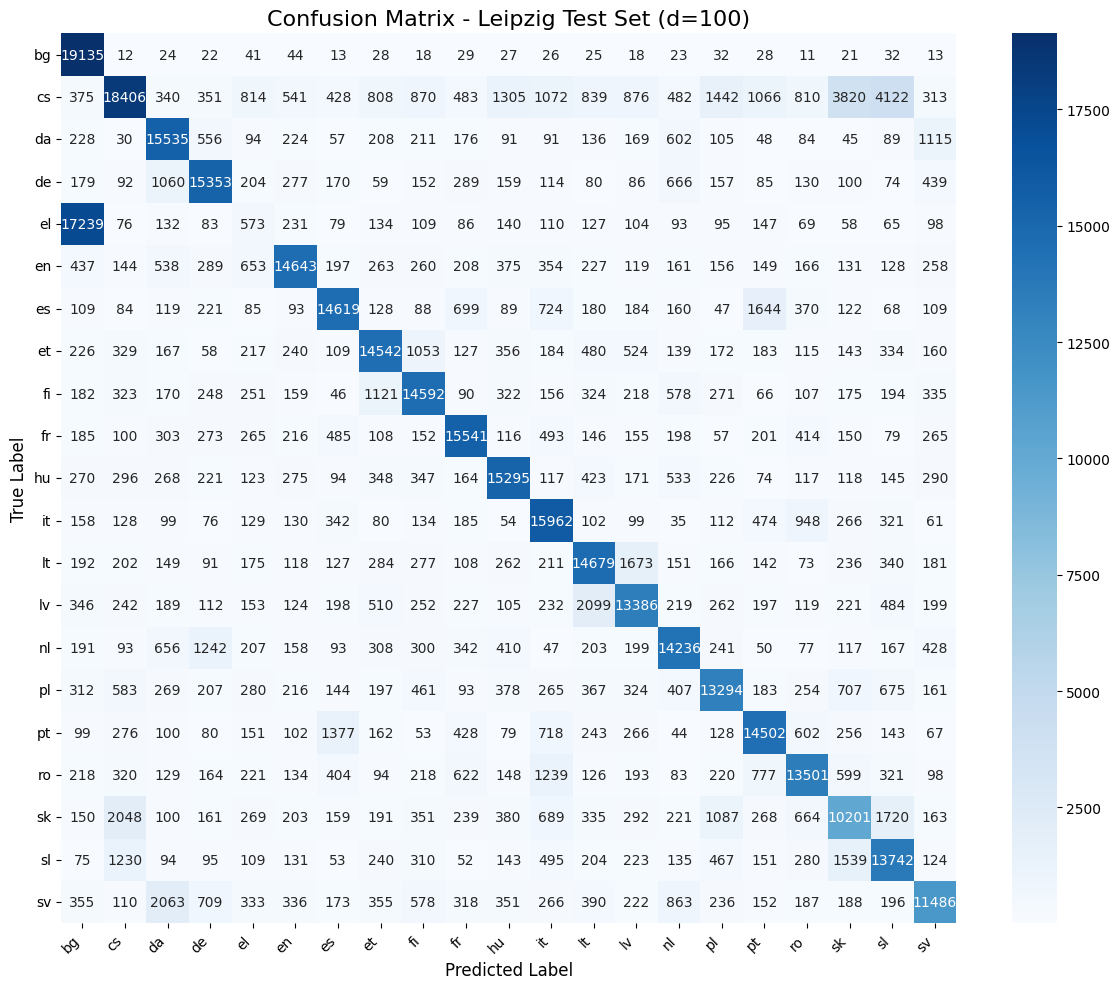

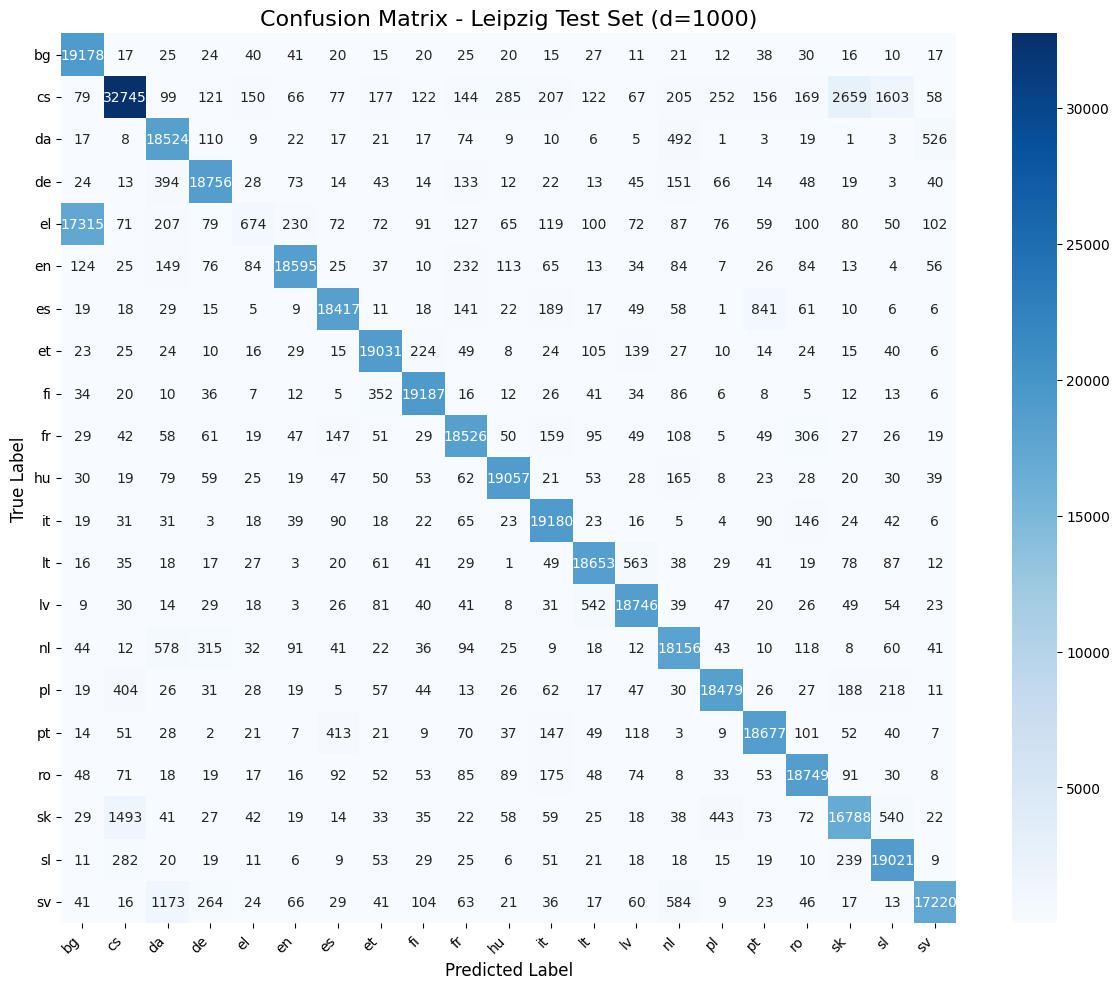

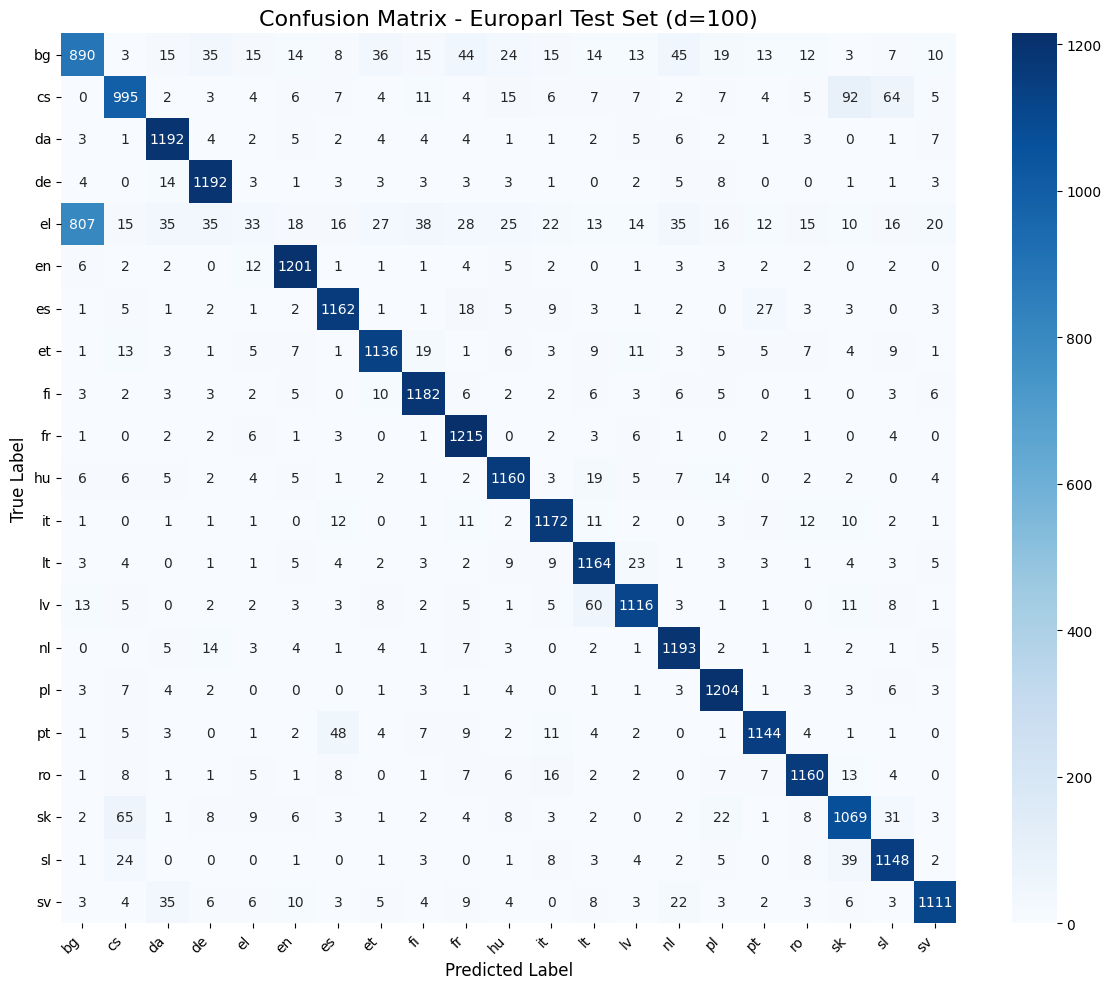

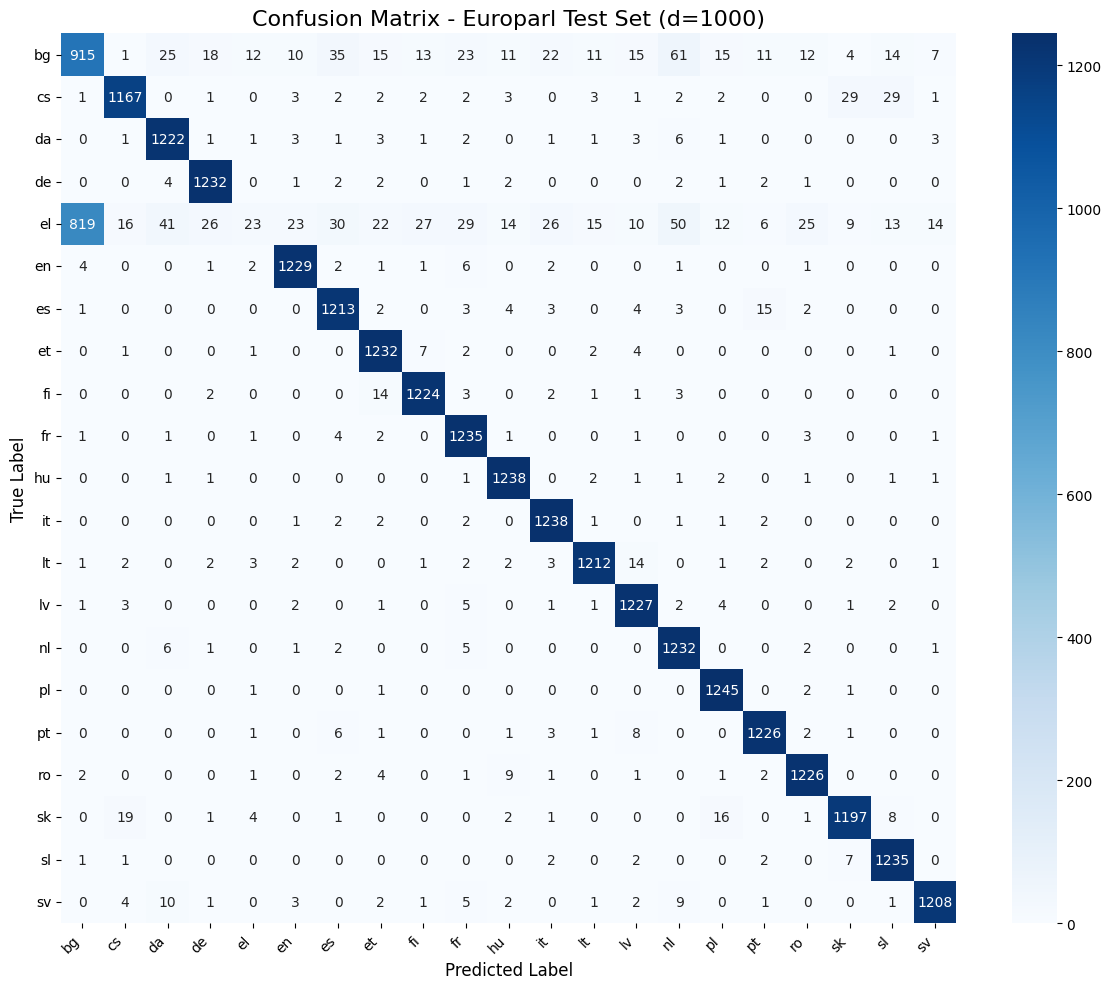

In [20]:
def plot_confusion_matrix(y_true, y_pred, labels, title, figsize=(12, 10)):

    cm = confusion_matrix(y_true, y_pred, labels=sorted(labels))
    
    plt.figure(figsize=figsize)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=sorted(labels),
        yticklabels=sorted(labels)
    )
    plt.title(title, fontsize=16)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Plot confusion matrices
print("\nGenerating confusion matrices...\n")

labels_100 = sorted(centroids_100.keys())
labels_1000 = sorted(centroids_1000.keys())

# Pre-compute predictions to avoid recomputing in plot calls
y_pred_leipzig_100 = [
    classify_text(text, centroids_100, item_memory_100, n=3)[0]
    for text in test_leipzig["cleaned_sentence"].values
]

y_pred_leipzig_1000 = [
    classify_text(text, centroids_1000, item_memory_1000, n=3)[0]
    for text in test_leipzig["cleaned_sentence"].values
]

y_pred_europarl_100 = [
    classify_text(text, centroids_100, item_memory_100, n=3)[0]
    for text in final_europarl_test_remapped["cleaned_sentence"].values
]

y_pred_europarl_1000 = [
    classify_text(text, centroids_1000, item_memory_1000, n=3)[0]
    for text in final_europarl_test_remapped["cleaned_sentence"].values
]

plot_confusion_matrix(
    test_leipzig['lang_code'].values, 
    y_pred_leipzig_100,
    labels_100,
    "Confusion Matrix - Leipzig Test Set (d=100)"
)

plot_confusion_matrix(
    test_leipzig['lang_code'].values, 
    y_pred_leipzig_1000,
    labels_1000,
    "Confusion Matrix - Leipzig Test Set (d=1000)"
)

plot_confusion_matrix(
    final_europarl_test_remapped['lang_code'].values, 
    y_pred_europarl_100,
    labels_100,
    "Confusion Matrix - Europarl Test Set (d=100)"
)

plot_confusion_matrix(
    final_europarl_test_remapped['lang_code'].values, 
    y_pred_europarl_1000,
    labels_1000,
    "Confusion Matrix - Europarl Test Set (d=1000)"
)


In [ ]:
print(f"Classification Report for Leipzig Test Set (d=100):\n{test_report_100}")
print(test_report_100)

print(f"Classification Report for Leipzig Test Set (d=1000):\n{test_report_1000}")
print(test_report_1000)

print(f"Classification Report for Europarl Test Set (d=100):\n{final_test_report_100}")
print(final_test_report_100)

print(f"Classification Report for Europarl Test Set (d=1000):\n{final_test_report_1000}")
print(final_test_report_1000)